<a href="https://colab.research.google.com/github/statftn/Deep-Learning-Theory-and-Practice/blob/main/chapter07_deep_dive_keras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This is a companion notebook for the book [Deep Learning with Python, Third Edition](https://www.manning.com/books/deep-learning-with-python-third-edition). For readability, it only contains runnable code blocks and section titles, and omits everything else in the book: text paragraphs, figures, and pseudocode.

**If you want to be able to follow what's going on, I recommend reading the notebook side by side with your copy of the book.**

The book's contents are available online at [deeplearningwithpython.io](https://deeplearningwithpython.io).

In [ ]:
!pip install keras keras-hub --upgrade -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 51.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 46.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.0/230.0 kB 12.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
keras-nlp 0.26.0 requires keras-hub==0.26.0, but you have keras-hub 0.32.0 which is incompatible.


In [ ]:
import os
os.environ["KERAS_BACKEND"] = "jax"   # jax: fastest among three keras backends

In [ ]:
# @title
import os
from IPython.core.magic import register_cell_magic

@register_cell_magic
def backend(line, cell):
    current, required = os.environ.get("KERAS_BACKEND", ""), line.split()[-1]
    if current == required:
        get_ipython().run_cell(cell)
    else:
        print(
            f"This cell requires the {required} backend. To run it, change KERAS_BACKEND to "
            f"\"{required}\" at the top of the notebook, restart the runtime, and rerun the notebook."
        )

## A deep dive on Keras

### A spectrum of workflows

### Different ways to build Keras models

#### The Sequential model

In [ ]:
import keras
from keras import layers

model = keras.Sequential(
    [
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ]
)

In [ ]:
model = keras.Sequential()
model.add(layers.Dense(64, activation="relu"))
model.add(layers.Dense(10, activation="softmax"))

In [ ]:
model.weights   # original input data dimension 모름 -> weights 형태 정해지지 않음

[]

In [ ]:
model.build(input_shape=(None, 3))   # 크기가 (3,)인 샘플 받기
model.weights
# dimension 64 -> 10

[<Variable path=sequential_1/dense_2/kernel, shape=(3, 64), dtype=float32, value=[[ 0.2305572   0.08944714  0.0909965  -0.09649996  0.28483343  0.11490375
    0.03050739  0.15729597  0.04869425  0.15610945  0.23392975  0.05213058
   -0.2571676   0.2809648   0.16278058  0.06408605 -0.0123145  -0.27134982
    0.13094515 -0.02134103 -0.26933977 -0.1782206  -0.21448785  0.19583377
   -0.21076137  0.24774837 -0.278543   -0.04413074  0.15459448  0.24601984
   -0.062617    0.26913947  0.19530204  0.04494345 -0.27914646  0.18469965
   -0.29631743  0.04791287 -0.25845712  0.10841435  0.29779518  0.03526947
    0.2724617   0.25853783  0.0020887   0.1099984  -0.2206034   0.05673969
   -0.2762621   0.15797019 -0.12025981 -0.27947995 -0.11287107 -0.16166486
   -0.11542052  0.06308189  0.17038864  0.13959959 -0.04318416 -0.26101986
   -0.15165196  0.29416245  0.10472089 -0.07300976]
  [-0.1763548  -0.06491353 -0.24389406  0.13157251  0.28256822 -0.2373617
   -0.14709863 -0.27828595  0.12542865  0.14

In [ ]:
model.summary(line_length=80)   # summary: 현재의 모델 구조 출력
# 3 * 64 + 64 = 256
# 650

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                   │ (None, 64)               │           256 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_3 (Dense)                   │ (None, 10)               │           650 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘

 Total params: 906 (3.54 KB)

 Trainable params: 906 (3.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 모델과 층에 이름을 지정
model = keras.Sequential(name="my_example_model")
model.add(layers.Dense(64, activation="relu", name="my_first_layer"))
model.add(layers.Dense(10, activation="softmax", name="my_last_layer"))
model.build((None, 3))
model.summary(line_length=80)   # build() 메서드 호출하기 전에는 summary()메서드 호출할 수 없다

Model: "my_example_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ my_first_layer (Dense)            │ (None, 64)               │           256 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ my_last_layer (Dense)             │ (None, 10)               │           650 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘

 Total params: 906 (3.54 KB)

 Trainable params: 906 (3.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model = keras.Sequential()
model.add(keras.Input(shape=(3,)))   # Input 클래스로 입력 크기를 미리 지정하면 Sequential 모델 가중치 생성 가능 -> summary()로 모델 확인
model.add(layers.Dense(64, activation="relu"))

In [ ]:
model.summary(line_length=80)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                   │ (None, 64)               │           256 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘

 Total params: 256 (1.00 KB)

 Trainable params: 256 (1.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.add(layers.Dense(10, activation="softmax"))
model.summary(line_length=80)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                   │ (None, 64)               │           256 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_5 (Dense)                   │ (None, 10)               │           650 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘

 Total params: 906 (3.54 KB)

 Trainable params: 906 (3.54 KB)

 Non-trainable params: 0 (0.00 B)

#### The Functional API

##### A simple example

In [ ]:
# Sequential model은 하나의 입력과 하나의 출력을 가지며 순서대로 층을 쌓은 모델만 표현할 수 있다
# 다중 입력, 다중 출력 또는 비선형적인 구조를 가진 모델의 경우에는 함수형 API를 사용한 모델을 만든다
inputs = keras.Input(shape=(3,), name="my_input")
features = layers.Dense(64, activation="relu")(inputs)
outputs = layers.Dense(10, activation="softmax")(features)
model = keras.Model(inputs=inputs, outputs=outputs, name="my_functional_model")

In [ ]:
inputs = keras.Input(shape=(3,), name="my_input")
# symbolic tensor: 실제 데이터를 가지고 있지는 않지만 사용할 모델이 보게 될 데이터 텐서의 사양이 인코딩되어 있다

In [ ]:
inputs.shape   # 3-dim tensor: 크기가 (3,)인 배치. 배치당 샘플의 개수는 가변적

(None, 3)

In [ ]:
inputs.dtype

'float32'

In [ ]:
features = layers.Dense(64, activation="relu")(inputs)

In [ ]:
features.shape

(None, 64)

In [ ]:
outputs = layers.Dense(10, activation="softmax")(features)
model = keras.Model(inputs=inputs, outputs=outputs, name="my_functional_model")   # outputs should be function of inputs
# 최종 출력을 얻은 후 입력과 출력을 Model 클래스에 전달하여 모델 객체를 생성

In [ ]:
model.summary(line_length=80)

Model: "my_functional_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ my_input (InputLayer)             │ (None, 3)                │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_8 (Dense)                   │ (None, 64)               │           256 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_9 (Dense)                   │ (None, 10)               │           650 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘

 Total params: 906 (3.54 KB)

 Trainable params: 906 (3.54 KB)

 Non-trainable params: 0 (0.00 B)

##### Multi-input, multi-output models

In [ ]:
vocabulary_size = 10000
num_tags = 100
num_departments = 4

# 모델의 입력을 정의
# three inputs: 이슈 티켓의 제목(텍스트), 이슈 티켓의 텍스트 본문(텍스트), 태그(범주형: one-hot encoded)
title = keras.Input(shape=(vocabulary_size,), name="title")   # 10000 dim vector
text_body = keras.Input(shape=(vocabulary_size,), name="text_body")   # 10000 dim vector
tags = keras.Input(shape=(num_tags,), name="tags")   # 100 dim vector

# 입력 특성을 하나의 tensor feature로 연결
features = layers.Concatenate()([title, text_body, tags])   # 10000 + 10000 + 100 = 20100 dim vector
# 중간층을 적용하여 입력 특성을 더 풍부한 표현으로 재결합
features = layers.Dense(64, activation="relu", name="dense_features")(features)

# 모델의 출력을 정의
# 2개의 출력: 이슈 티켓의 우선순위 점수로 0~1 사이 스칼라(sigmoid), 이슈 티켓을 처리해야 할 부서(softmax)
priority = layers.Dense(1, activation="sigmoid", name="priority")(features)
department = layers.Dense(
    num_departments, activation="softmax", name="department"
)(features)   # classify

# 입력과 출력을 지정하여 모델을 만들기
model = keras.Model(
    inputs=[title, text_body, tags],
    outputs=[priority, department],
)

##### Training a multi-input, multi-output model

In [ ]:
import numpy as np

num_samples = 1280

# 더미 입력 데이터
# randomly generate data -> train
title_data = np.random.randint(0, 2, size=(num_samples, vocabulary_size))   # 0과 1로 이루어진 무작위 2차원 배열
text_body_data = np.random.randint(0, 2, size=(num_samples, vocabulary_size))
tags_data = np.random.randint(0, 2, size=(num_samples, num_tags))
# random: 무작위 값을 생성
# randint: 정수를 무작위로 생성
# randint(0, 2)는 0과 1만 생성. 끝값인 2는 포함되지 않는다

In [ ]:
title_data.shape

(1280, 10000)

In [ ]:
text_body_data.shape

(1280, 10000)

In [ ]:
tags_data.shape

(1280, 100)

In [ ]:
# 더미 타깃 데이터
priority_data = np.random.random(size=(num_samples, 1))   # 0 이상 1 미만의 실수(float)를 무작위로 생성
department_data = np.random.randint(0, num_departments, size=(num_samples, 1))

In [ ]:
priority_data.shape

(1280, 1)

In [ ]:
priority_data[:10]

array([[0.82218469],
       [0.10426019],
       [0.64446848],
       [0.69842695],
       [0.05855439],
       [0.82172904],
       [0.53732325],
       [0.02044593],
       [0.75854539],
       [0.5255368 ]])

In [ ]:
department_data[:5]

array([[0],
       [2],
       [0],
       [0],
       [2]])

In [ ]:
import numpy as np

num_samples = 1280

# randomly generate data -> train
title_data = np.random.randint(0, 2, size=(num_samples, vocabulary_size))
text_body_data = np.random.randint(0, 2, size=(num_samples, vocabulary_size))
tags_data = np.random.randint(0, 2, size=(num_samples, num_tags))

priority_data = np.random.random(size=(num_samples, 1))
department_data = np.random.randint(0, num_departments, size=(num_samples, 1))

# list-like format
# 모델 학습 방법 설정
model.compile(
    optimizer="adam",
    loss=["mean_squared_error", "sparse_categorical_crossentropy"],
    metrics=[["mean_absolute_error"], ["accuracy"]],
)   # sparse_categorical_crossentropy: 정수 표현으로 분류 (categorical_crossentropy: one-hot encoded)
# 모델 학습
model.fit(
    [title_data, text_body_data, tags_data],
    [priority_data, department_data],
    epochs=1,
)
# 학습된 모델의 성능을 평가
model.evaluate(
    [title_data, text_body_data, tags_data], [priority_data, department_data]
)
# 학습된 딥러닝 모델을 이용해 새로운 입력 데이터의 예측 결과를 계산
priority_preds, department_preds = model.predict(
    [title_data, text_body_data, tags_data]
)

40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - department_accuracy: 0.2414 - department_loss: 5.6325 - loss: 5.9443 - priority_loss: 0.3118 - priority_mean_absolute_error: 0.4764
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - department_accuracy: 0.5555 - department_loss: 4.5599 - loss: 4.8779 - priority_loss: 0.3180 - priority_mean_absolute_error: 0.4826
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [ ]:
# dictionary format
# 입력과 출력이 많고, 입력 순서에 신경 쓰고 싶지 않다면
# Input객체와 출력 층에 부여한 이름을 활용해서 데이터를 딕셔너리로 전달 가능
model.compile(
    optimizer="adam",
    loss={
        "priority": "mean_squared_error",
        "department": "sparse_categorical_crossentropy",
    },
    metrics={
        "priority": ["mean_absolute_error"],
        "department": ["accuracy"],
    },
)
model.fit(
    {"title": title_data, "text_body": text_body_data, "tags": tags_data},
    {"priority": priority_data, "department": department_data},
    epochs=1,
)
model.evaluate(
    {"title": title_data, "text_body": text_body_data, "tags": tags_data},
    {"priority": priority_data, "department": department_data},
)
priority_preds, department_preds = model.predict(
    {"title": title_data, "text_body": text_body_data, "tags": tags_data}
)

40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - department_accuracy: 0.3477 - department_loss: 5.2292 - loss: 5.5472 - priority_loss: 0.3180 - priority_mean_absolute_error: 0.4826
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - department_accuracy: 0.4109 - department_loss: 4.6778 - loss: 4.9958 - priority_loss: 0.3180 - priority_mean_absolute_error: 0.4826
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


##### The power of the Functional API: Access to layer connectivity

###### Plotting layer connectivity

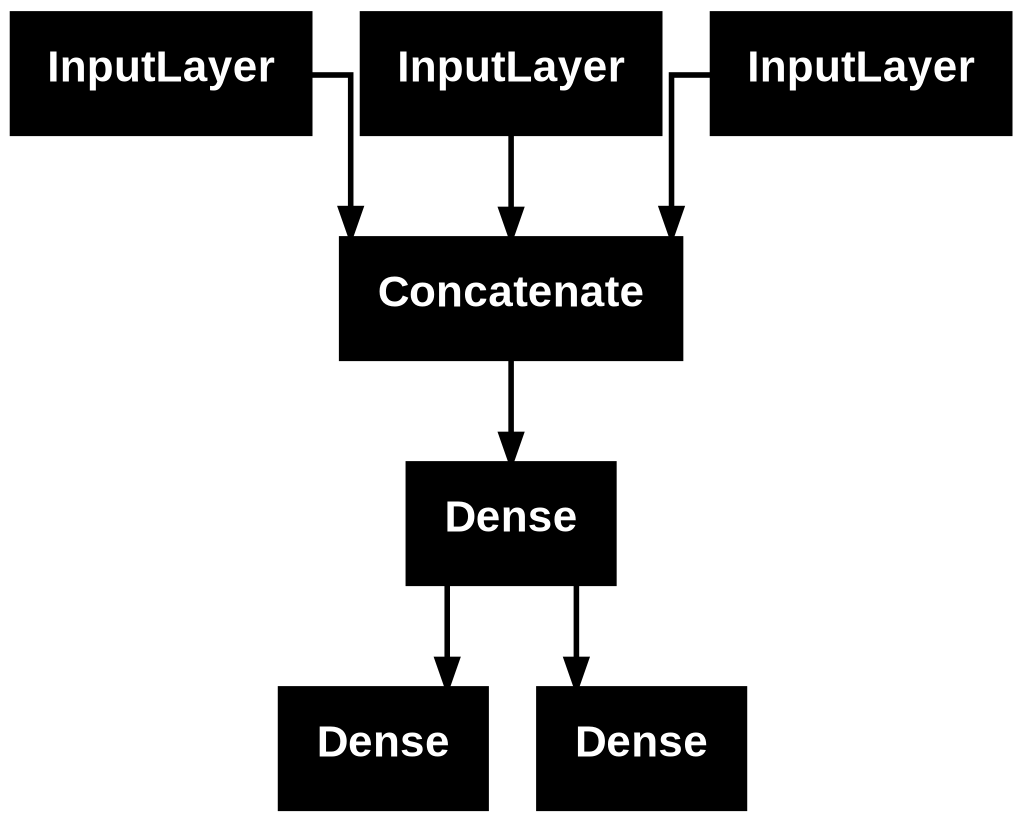

In [ ]:
keras.utils.plot_model(model, "ticket_classifier.png")   # 함수형 딥러닝 모델의 구조를 그림으로 시각화

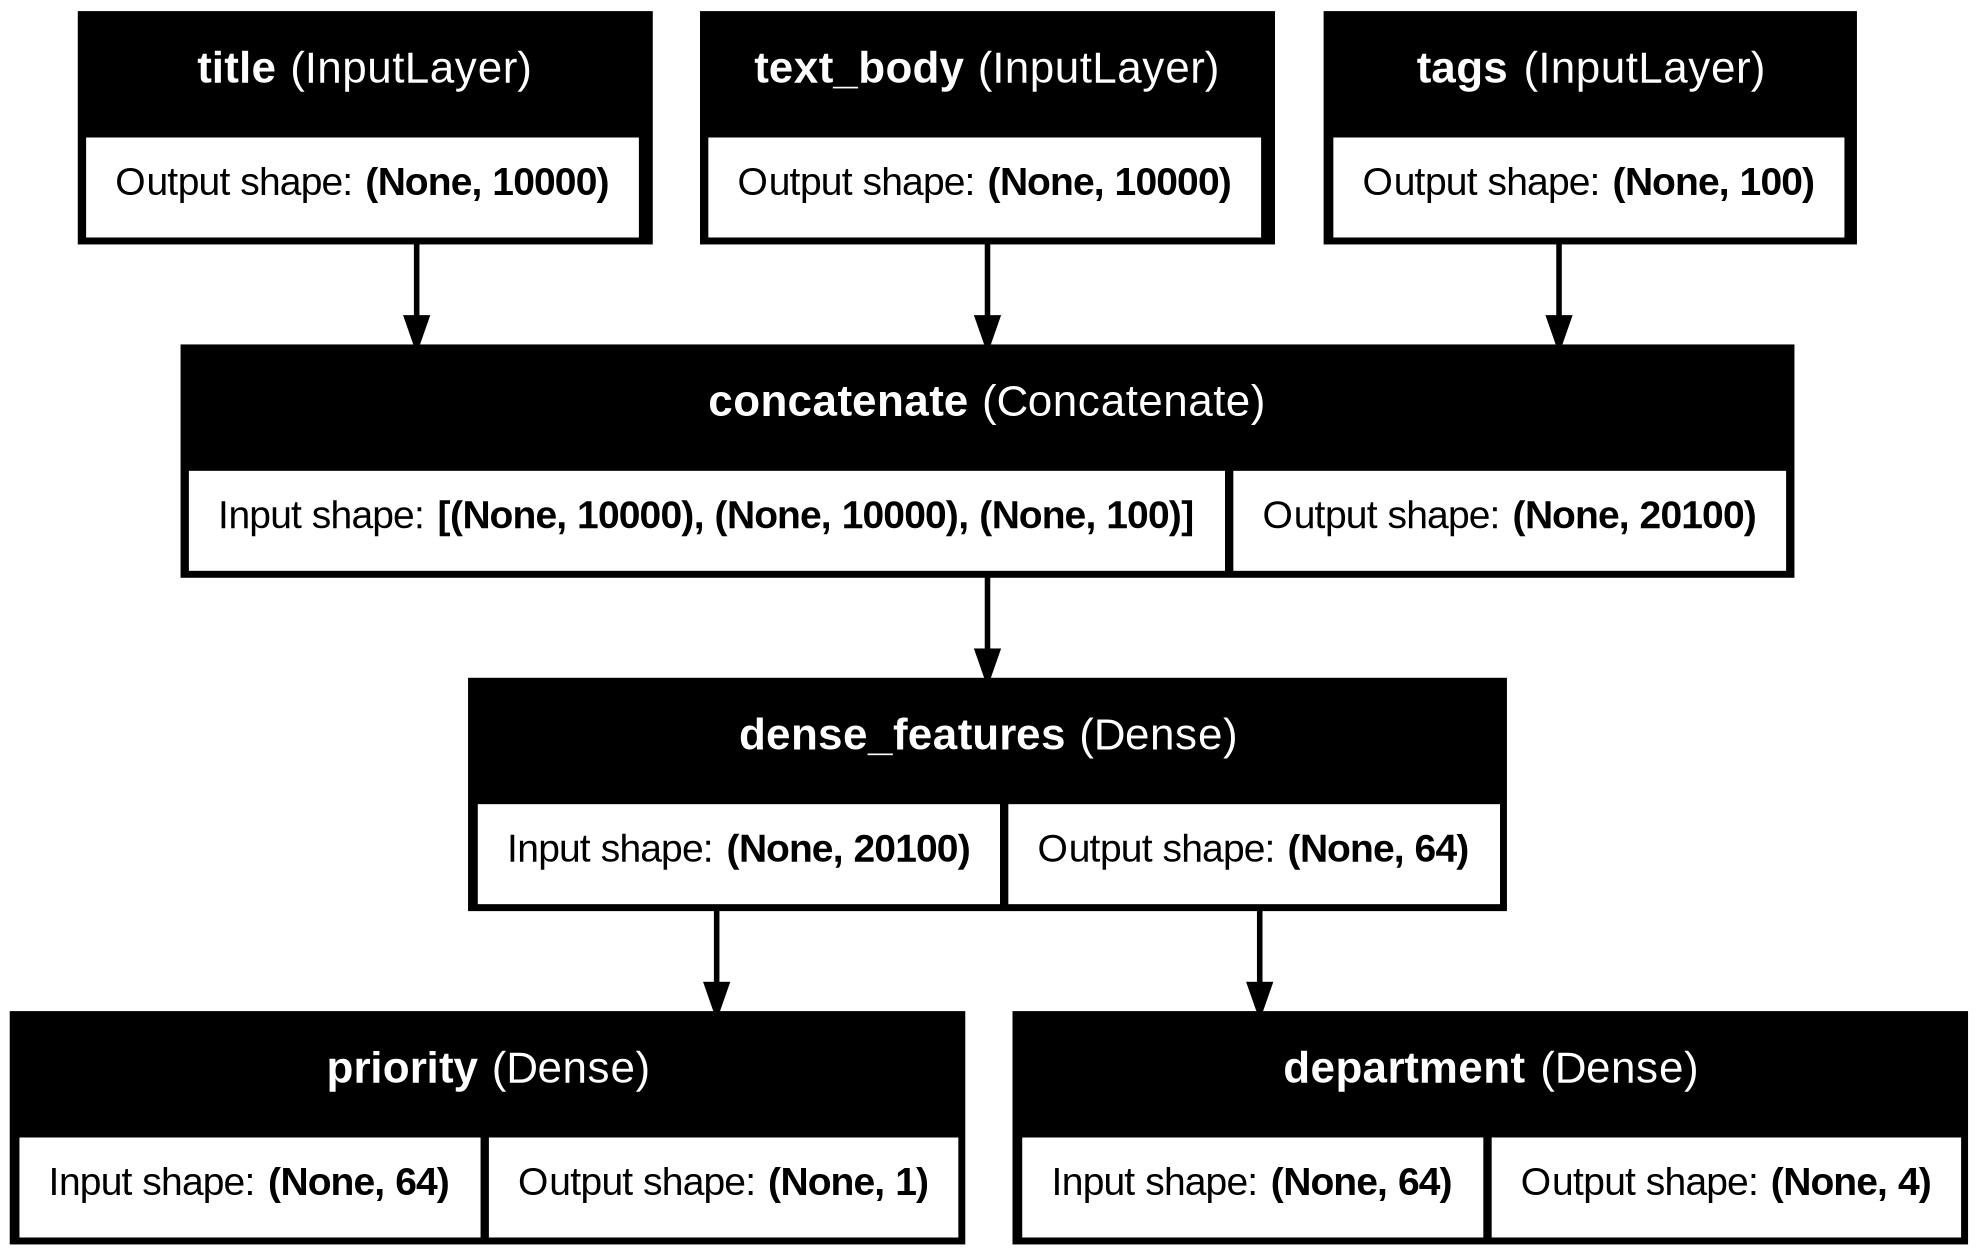

In [ ]:
keras.utils.plot_model(
    model,
    "ticket_classifier_with_shape_info.png",
    show_shapes=True,
    show_layer_names=True,
)
# show_shapes=True: 각 층의 입출력 크기 표시
# show_layer_names=True: 층 이름 표시
# show_dtype=True: 층의 dtype 표시
# show_layer_activations=True: 층의 활성화함수 표시
# dpi로 해상도 지정 가능 (기본값은 96)

###### Feature extraction with a Functional model

In [ ]:
model.layers

[<InputLayer name=title, built=True>,
 <InputLayer name=text_body, built=True>,
 <InputLayer name=tags, built=True>,
 <Concatenate name=concatenate, built=True>,
 <Dense name=dense_features, built=True>,
 <Dense name=priority, built=True>,
 <Dense name=department, built=True>]

In [ ]:
model.layers[3]

<Concatenate name=concatenate, built=True>

In [ ]:
model.layers[3].input

[<KerasTensor shape=(None, 10000), dtype=float32, sparse=False, ragged=False, name=title>,
 <KerasTensor shape=(None, 10000), dtype=float32, sparse=False, ragged=False, name=text_body>,
 <KerasTensor shape=(None, 100), dtype=float32, sparse=False, ragged=False, name=tags>]

In [ ]:
model.layers[3].output

<KerasTensor shape=(None, 20100), dtype=float32, sparse=False, ragged=False, name=keras_tensor_14>

In [ ]:
features = model.layers[4].output
difficulty = layers.Dense(3, activation="softmax", name="difficulty")(features)
# 이슈 티켓이 해결되는 데 걸리는 시간을 추정
new_model = keras.Model(
    inputs=[title, text_body, tags], outputs=[priority, department, difficulty]
)

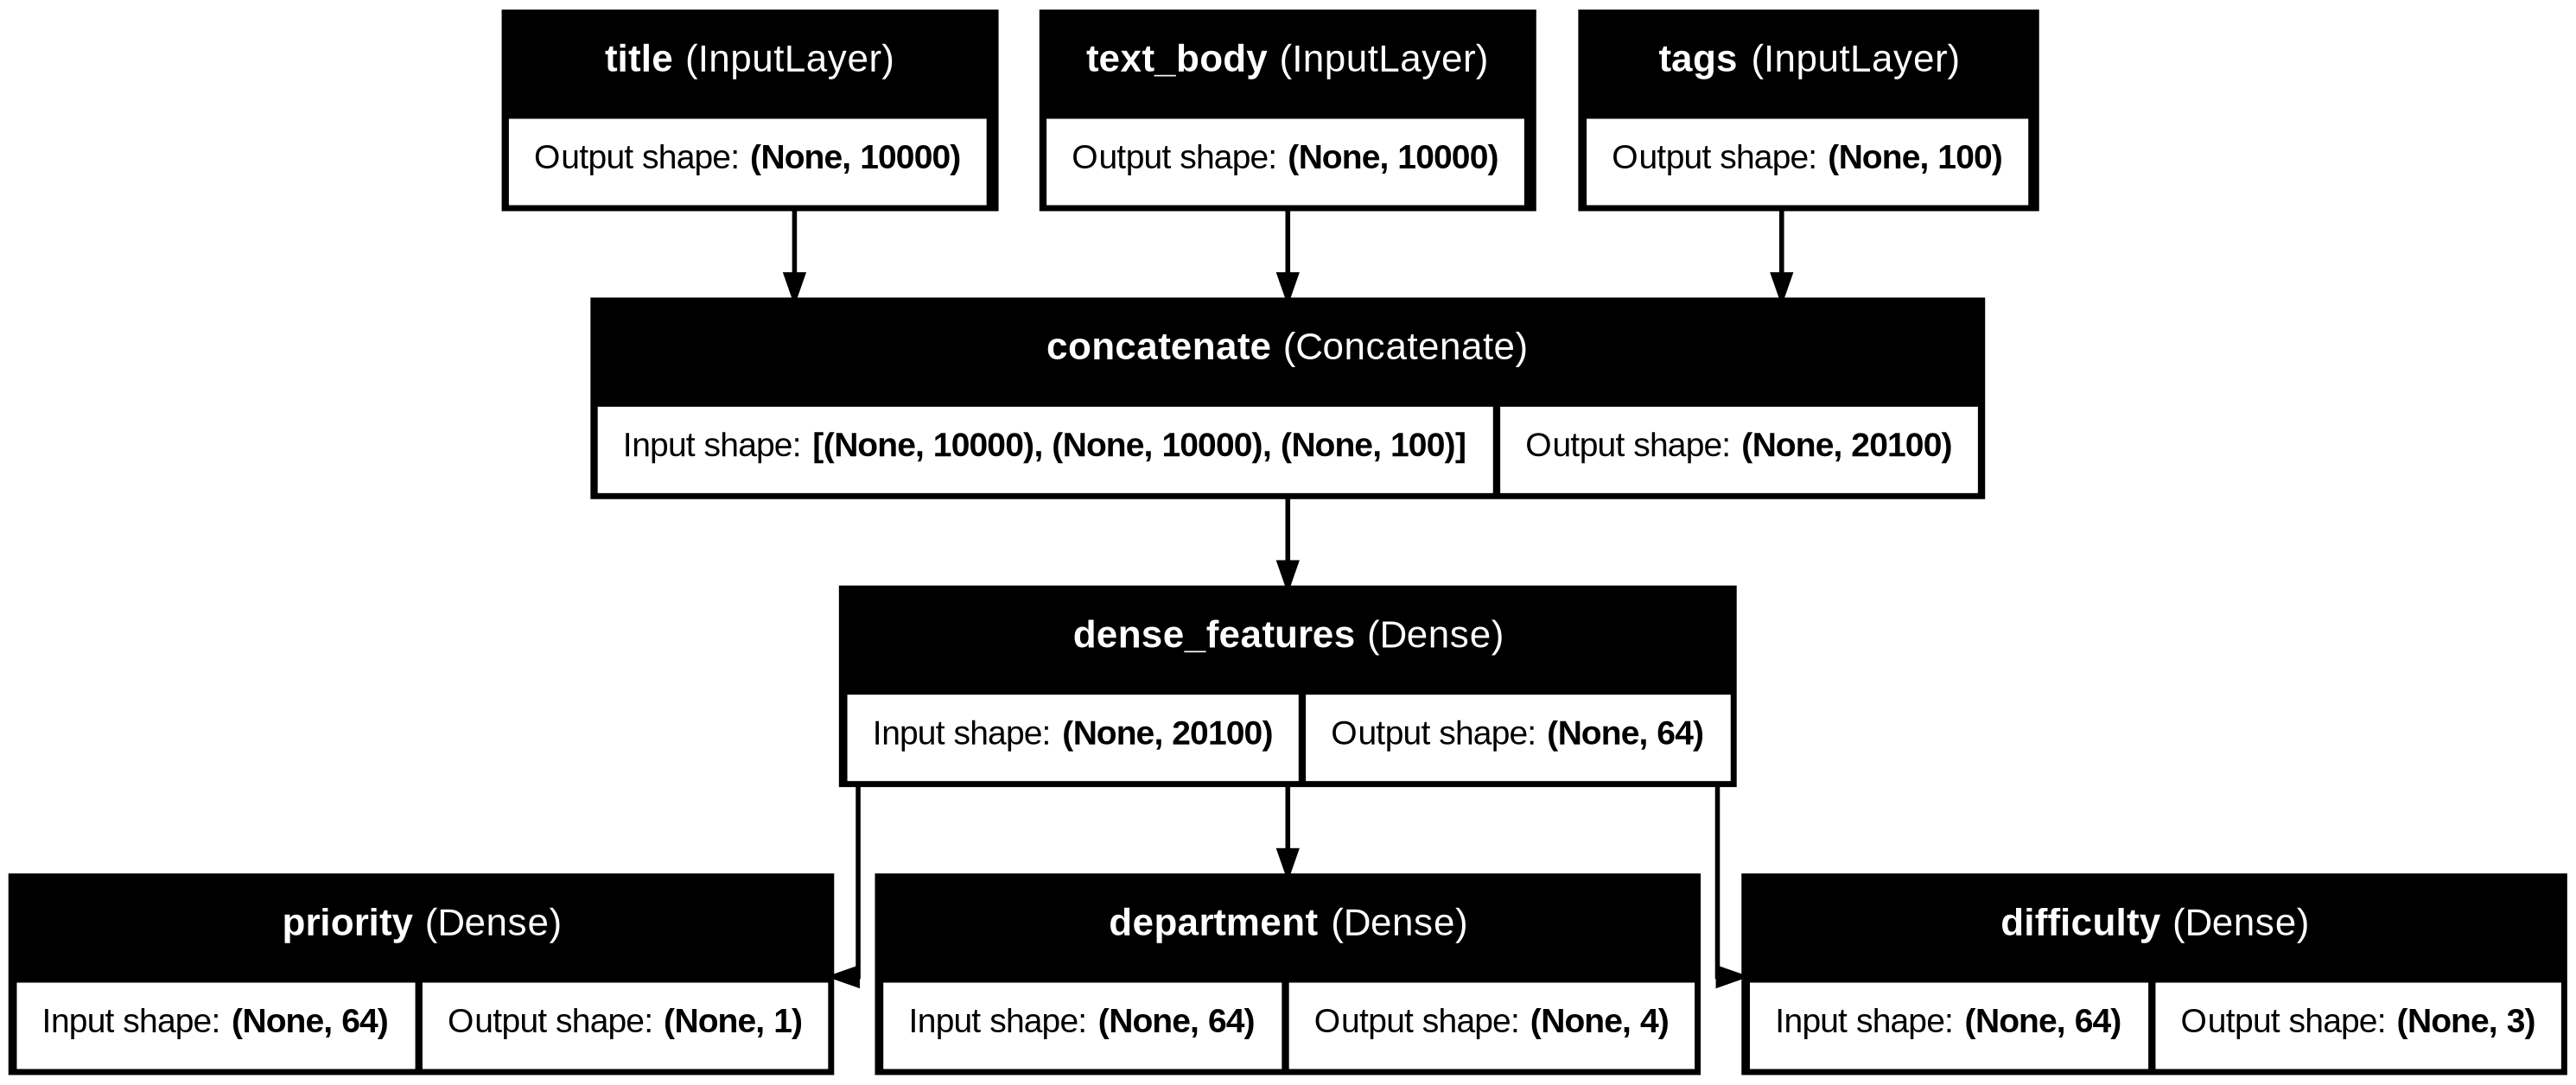

In [ ]:
keras.utils.plot_model(
    new_model,
    "updated_ticket_classifier.png",
    show_shapes=True,
    show_layer_names=True,
)

Some questions

In [ ]:
# From Multi-input, multi-output example, modify your functional model

vocabulary_size = 10000
num_tags = 100
num_departments = 4

title = keras.Input(shape=(vocabulary_size,), name="title")   # 10000 dim vector
text_body = keras.Input(shape=(vocabulary_size,), name="text_body")   # 10000 dim vector
tags = keras.Input(shape=(num_tags,), name="tags")   # 100 dim vector

features = layers.Concatenate()([title, text_body, tags])   # 10000 + 10000 + 100 = 20100 dim vector
features = layers.Dense(64, activation="relu", name="dense_11")(features)
features = layers.Dense(36, activation="relu", name="dense_12")(features)
features = layers.Dense(24, activation="relu", name="dense_13")(features)

priority = layers.Dense(1, activation="sigmoid", name="priority")(features)
department = layers.Dense(
    num_departments, activation="softmax", name="department"
)(features)

model = keras.Model(
    inputs=[title, text_body, tags],
    outputs=[priority, department],
)

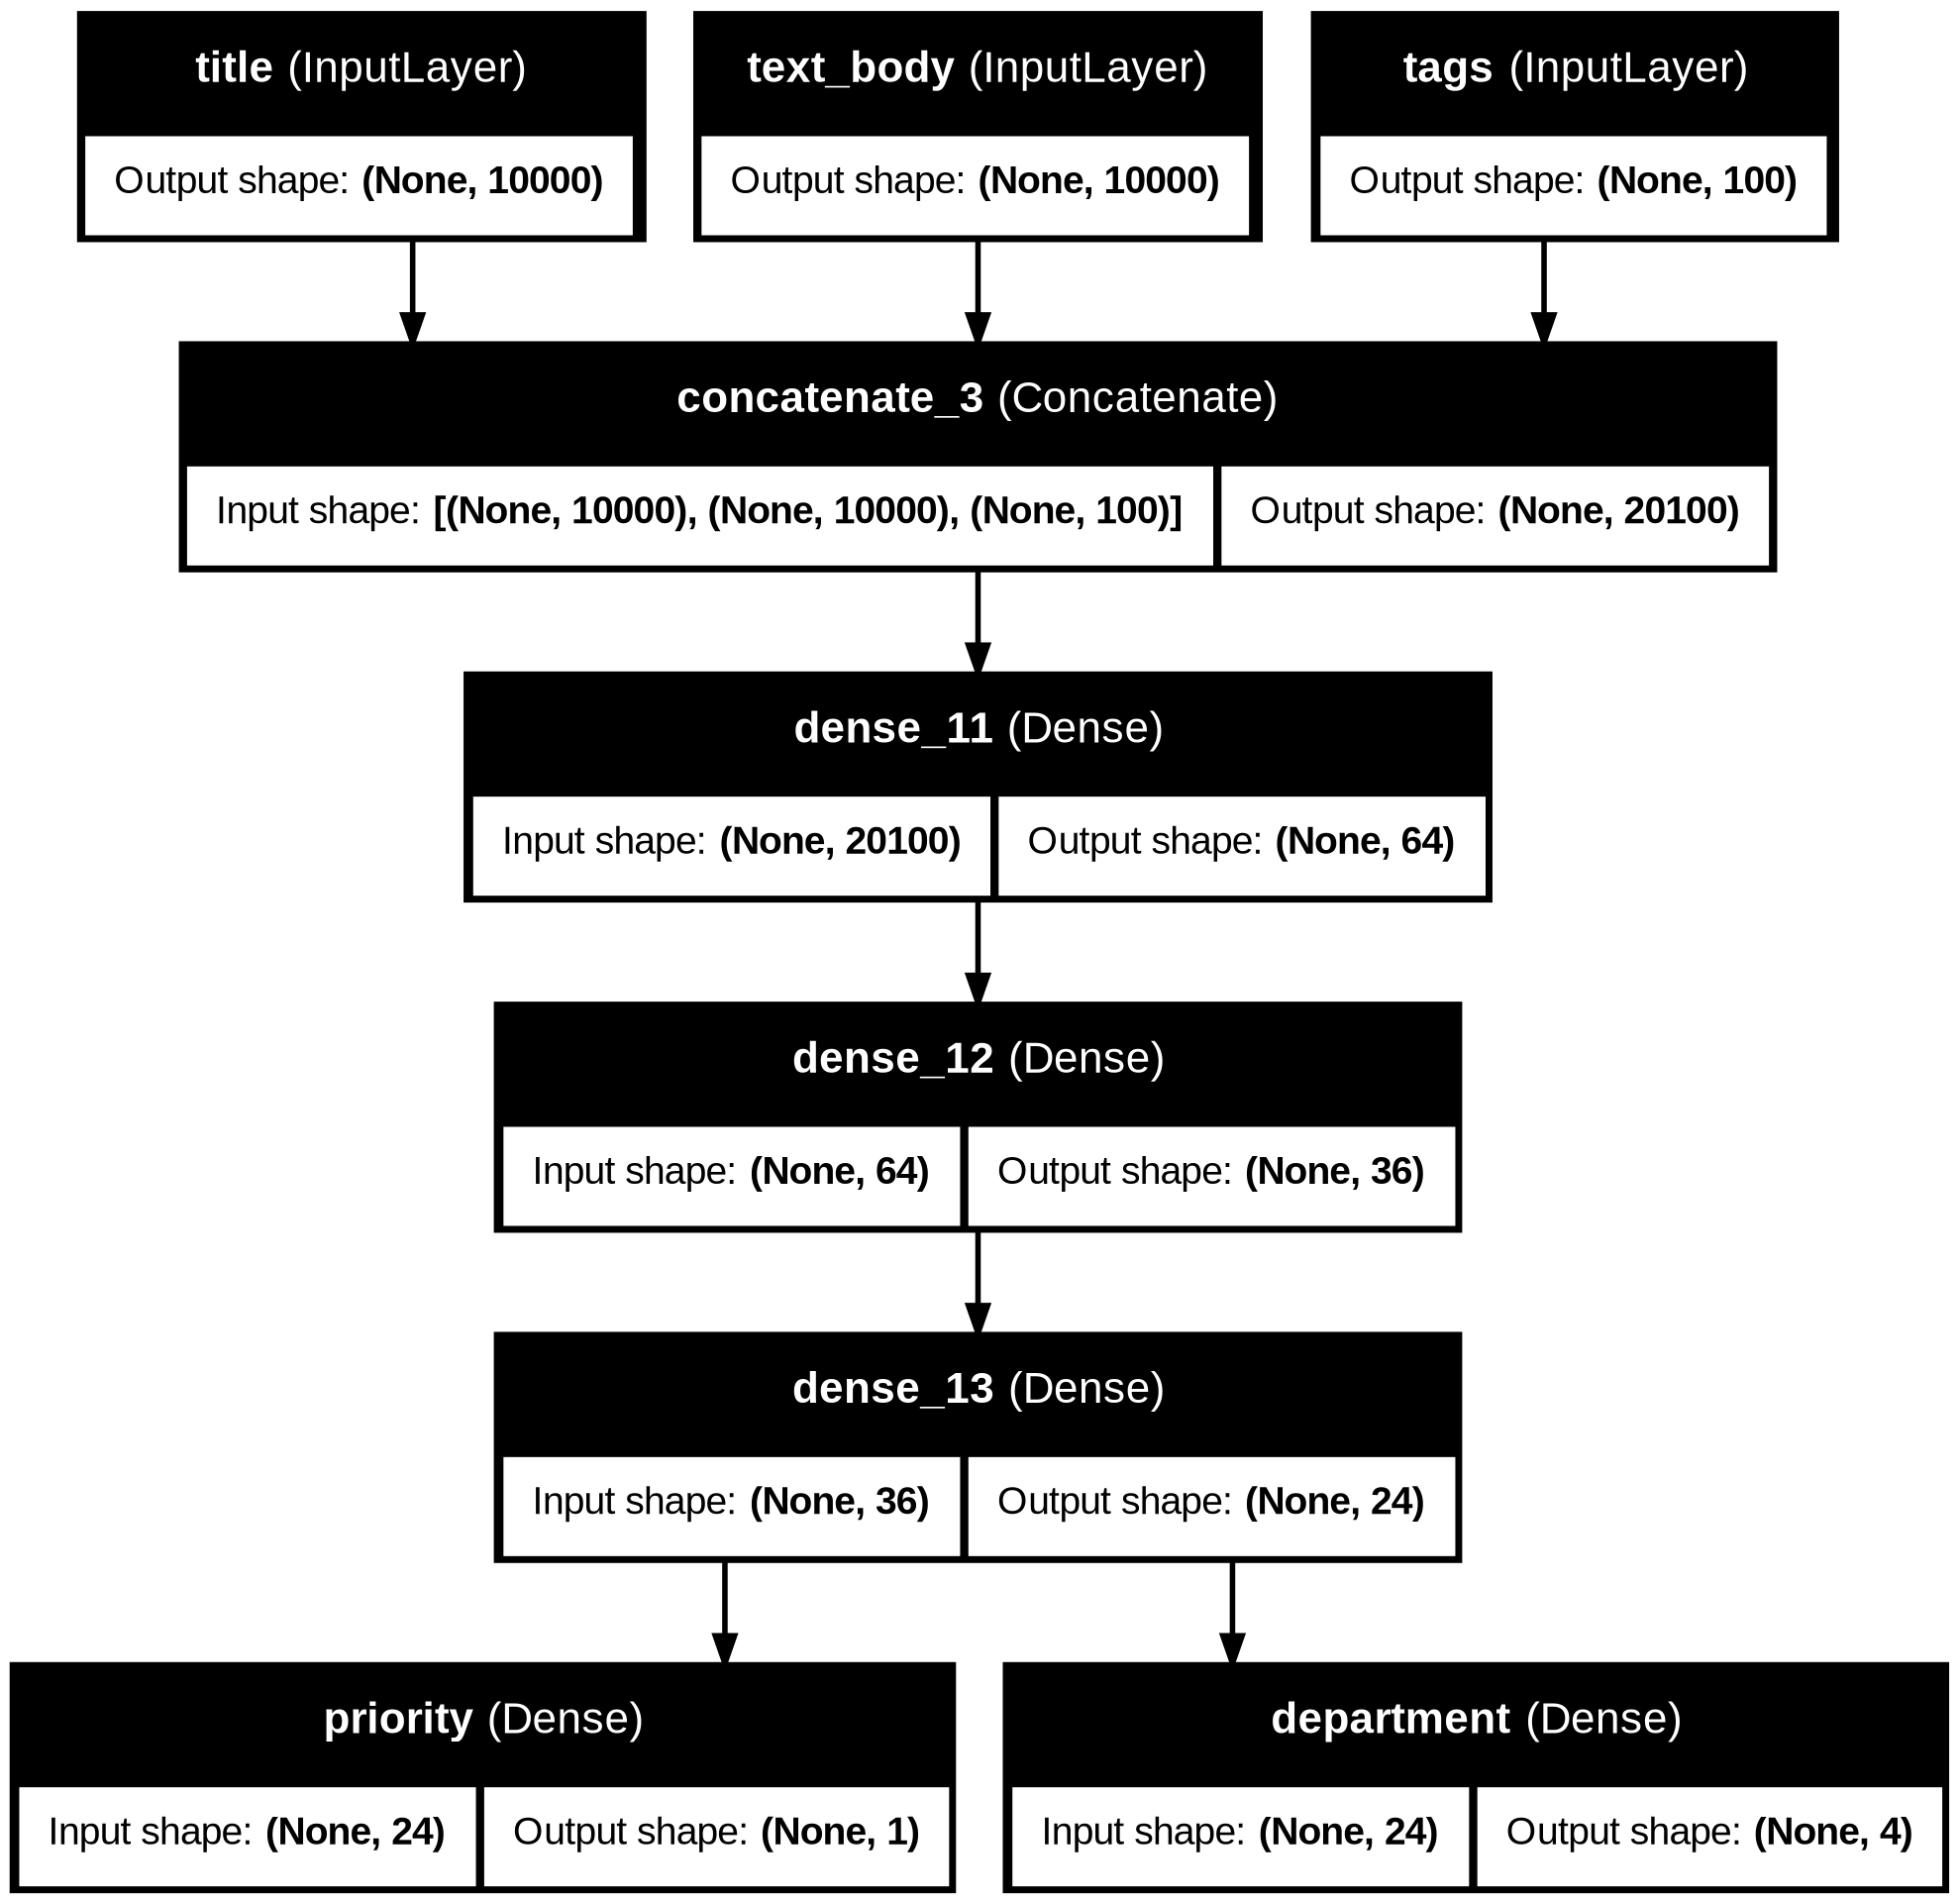

In [ ]:
keras.utils.plot_model(
    model,
    "ticket_classifier_with_shape_info.png",
    show_shapes=True,
    show_layer_names=True,
)

In [ ]:
# Try to add difficulty output

vocabulary_size = 10000
num_tags = 100
num_departments = 4

title = keras.Input(shape=(vocabulary_size,), name="title")   # 10000 dim vector
text_body = keras.Input(shape=(vocabulary_size,), name="text_body")   # 10000 dim vector
tags = keras.Input(shape=(num_tags,), name="tags")   # 100 dim vector

features = layers.Concatenate()([title, text_body, tags])   # 10000 + 10000 + 100 = 20100 dim vector
features = layers.Dense(64, activation="relu", name="dense_11")(features)
features = layers.Dense(36, activation="relu", name="dense_12")(features)
features = layers.Dense(24, activation="relu", name="dense_13")(features)

priority = layers.Dense(1, activation="sigmoid", name="priority")(features)
department = layers.Dense(
    num_departments, activation="softmax", name="department"
)(features)

model = keras.Model(
    inputs=[title, text_body, tags],
    outputs=[priority, department],
)

In [ ]:
model.layers

[<InputLayer name=title, built=True>,
 <InputLayer name=text_body, built=True>,
 <InputLayer name=tags, built=True>,
 <Concatenate name=concatenate_5, built=True>,
 <Dense name=dense_11, built=True>,
 <Dense name=dense_12, built=True>,
 <Dense name=dense_13, built=True>,
 <Dense name=priority, built=True>,
 <Dense name=department, built=True>]

In [ ]:
model.layers[5]

<Dense name=dense_12, built=True>

In [ ]:
model.layers[5].input

<KerasTensor shape=(None, 64), dtype=float32, sparse=False, ragged=False, name=keras_tensor_69>

In [ ]:
model.layers[5].output

<KerasTensor shape=(None, 36), dtype=float32, sparse=False, ragged=False, name=keras_tensor_70>

In [ ]:
features = model.layers[5].output
difficulty = layers.Dense(3, activation="softmax", name="difficulty")(features)

new_model = keras.Model(
    inputs=[title, text_body, tags], outputs=[priority, department, difficulty]
)

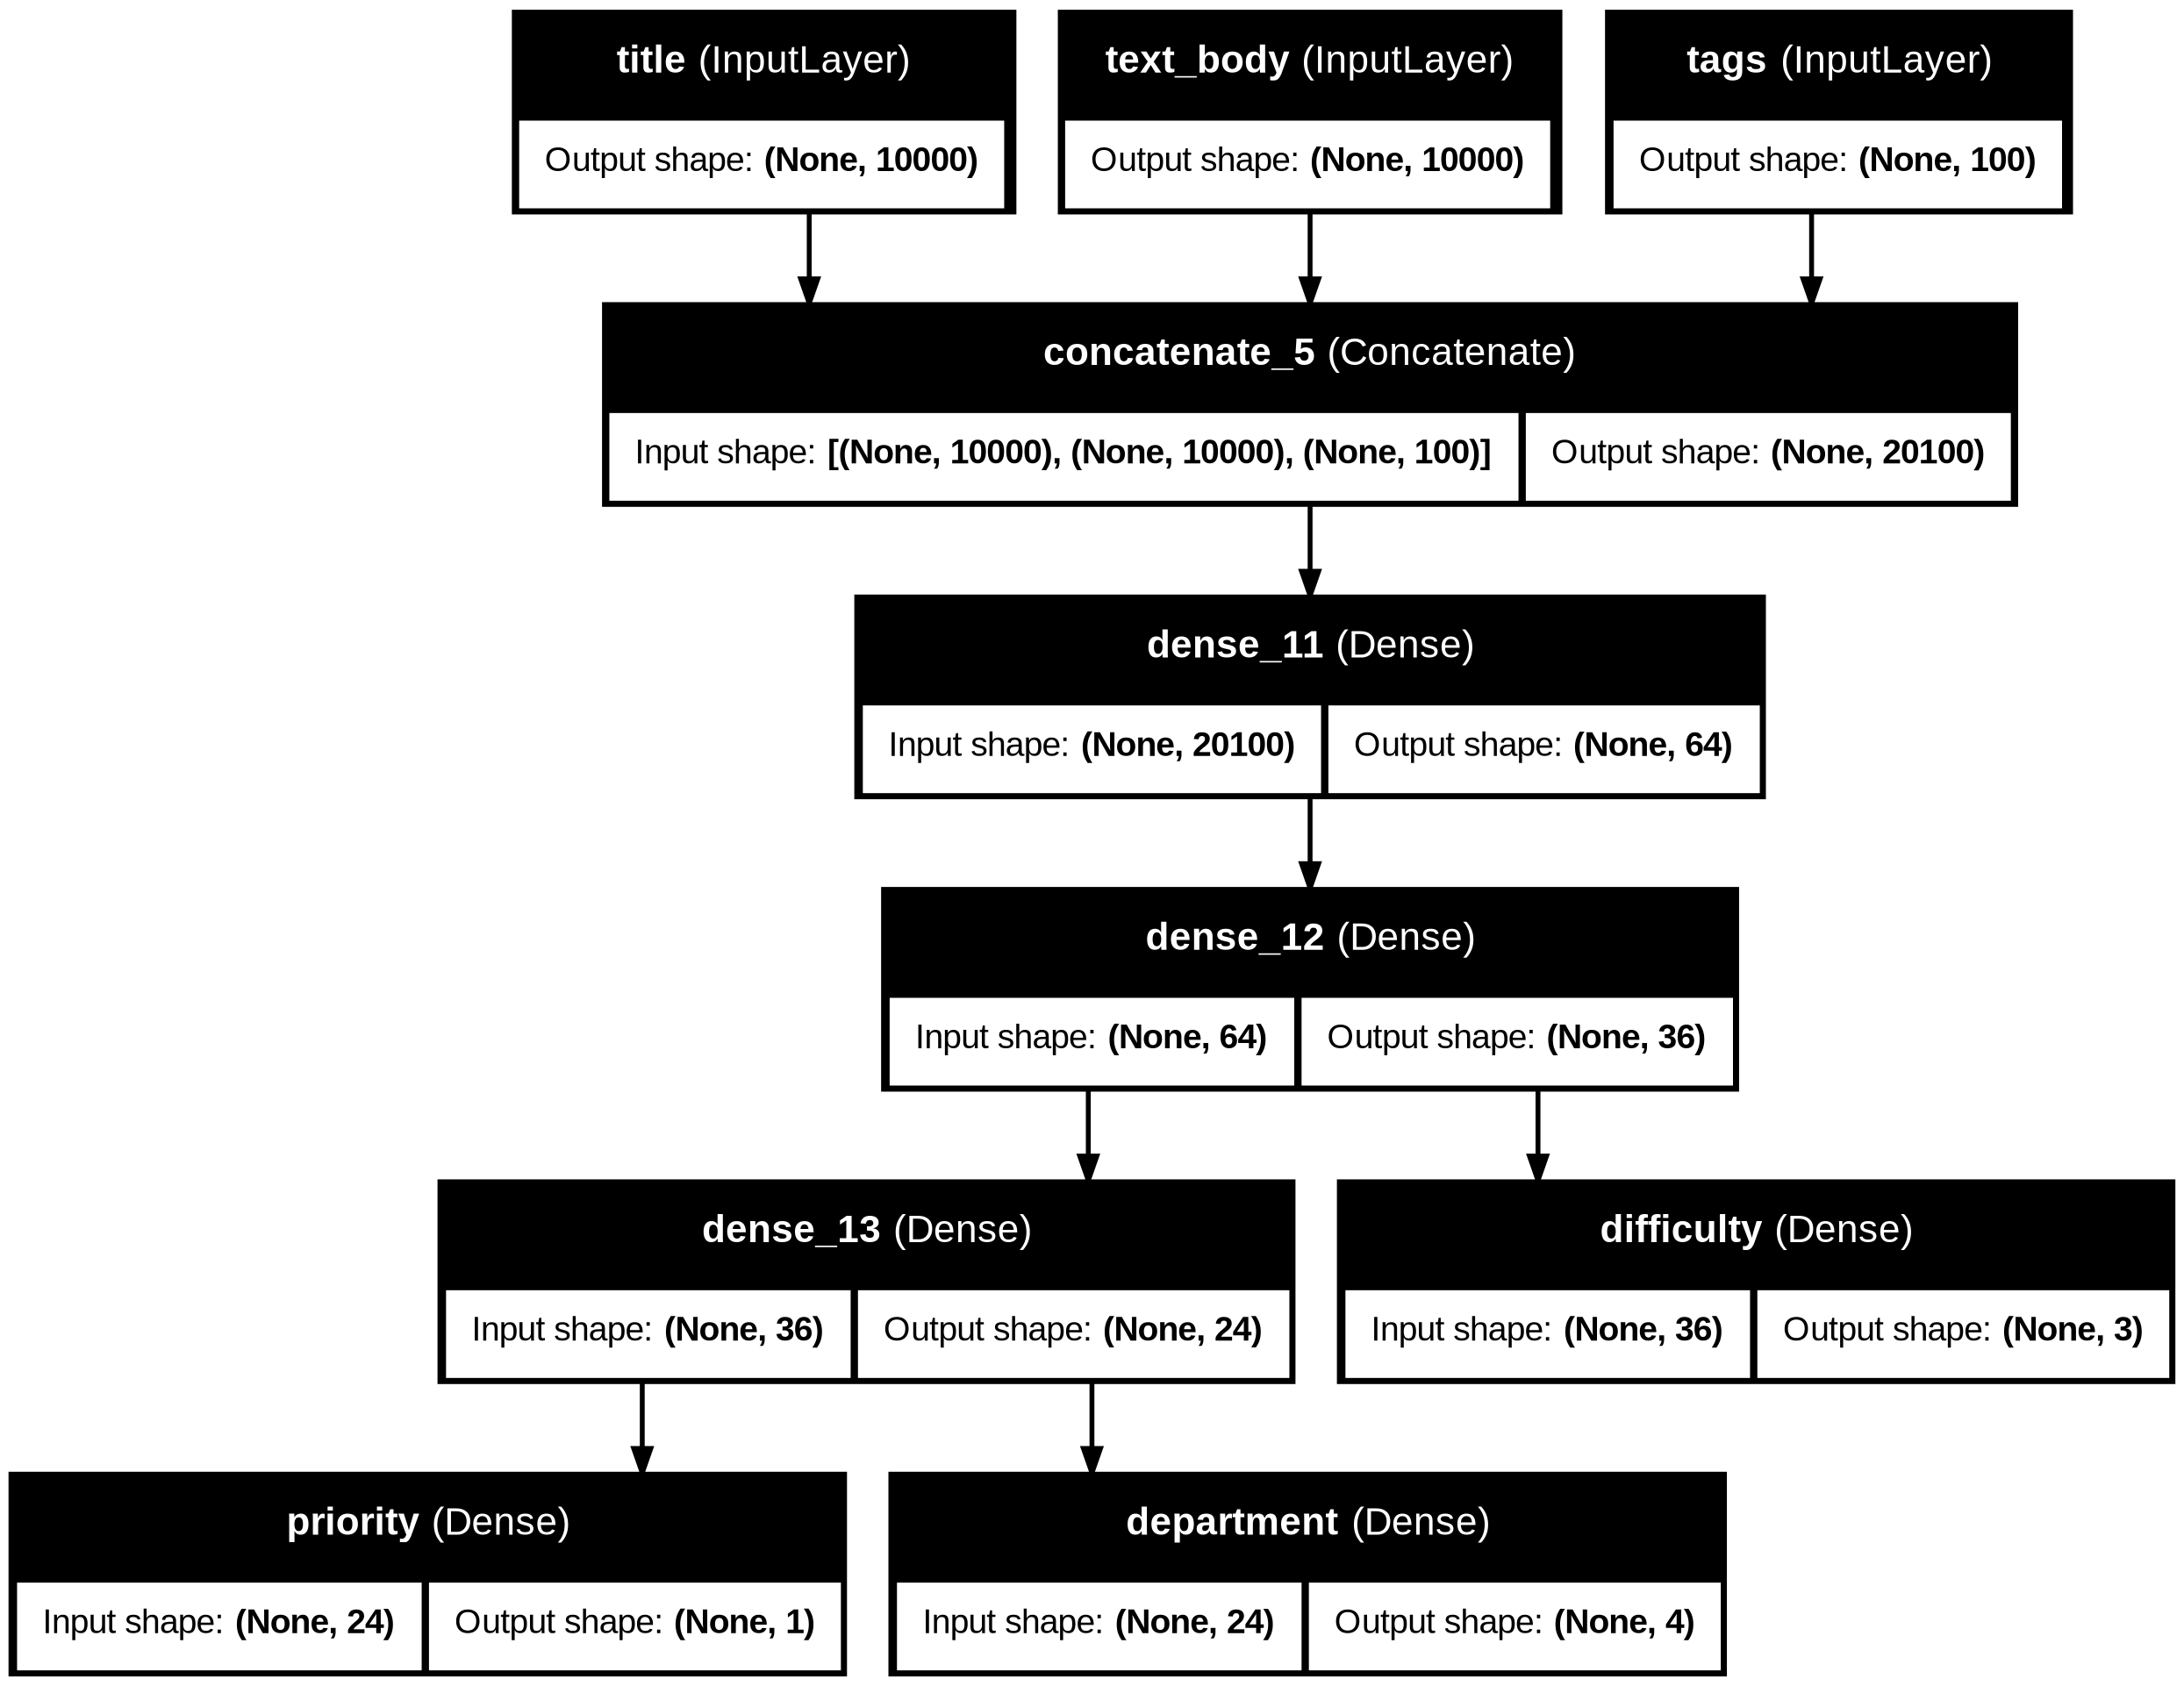

In [ ]:
keras.utils.plot_model(
    new_model,
    "updated_ticket_classifier.png",
    show_shapes=True,
    show_layer_names=True,
)

#### Subclassing the Model class

##### Rewriting our previous example as a subclassed model

In [ ]:
class CustomerTicketModel(keras.Model):
    def __init__(self, num_departments):   # 모델이 사용할 층을 정의 (__init__(): 모델 객체가 생성될 때 실행되는 초기화 메서드)
        super().__init__()   # Keras 모델이 필요한 기능을 정상적으로 사용할 수 있도록 부모 클래스인 keras.Model의 초기화 코드를 실행
        self.concat_layer = layers.Concatenate()
        self.mixing_layer = layers.Dense(64, activation="relu")
        self.priority_scorer = layers.Dense(1, activation="sigmoid")
        self.department_classifier = layers.Dense(
            num_departments, activation="softmax"
        )

    def call(self, inputs):   # call(): 앞서 만든 층을 사용하여 모델의 정방향 패스 정의
        title = inputs["title"]
        text_body = inputs["text_body"]
        tags = inputs["tags"]

        features = self.concat_layer([title, text_body, tags])
        features = self.mixing_layer(features)
        priority = self.priority_scorer(features)
        department = self.department_classifier(features)
        return priority, department

In [ ]:
model = CustomerTicketModel(num_departments=4)

priority, department = model(
    {"title": title_data, "text_body": text_body_data, "tags": tags_data}
)

In [ ]:
model.compile(
    optimizer="adam",
    loss=["mean_squared_error", "sparse_categorical_crossentropy"],
    metrics=[["mean_absolute_error"], ["accuracy"]],
)   # 손실과 평가 지표로 전달하는 값은 call()메서드가 반환하는 것과 정확히 일치해야 한다 (여기서는 2개의 원소를 가진 리스트)
model.fit(
    {"title": title_data, "text_body": text_body_data, "tags": tags_data},
    [priority_data, department_data],
    epochs=1,
)   # 입력 데이터 구조, 타깃 데이터의 구조는 call()에서의 구조와 같아야 한다
model.evaluate(
    {"title": title_data, "text_body": text_body_data, "tags": tags_data},
    [priority_data, department_data],
)
priority_preds, department_preds = model.predict(
    {"title": title_data, "text_body": text_body_data, "tags": tags_data}
)

40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.2500 - loss: 5.9784 - mean_absolute_error: 0.3263 - mean_squared_error_loss: 0.1609 - sparse_categorical_crossentropy_loss: 5.8176
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4141 - loss: 4.9921 - mean_absolute_error: 0.2560 - mean_squared_error_loss: 0.0932 - sparse_categorical_crossentropy_loss: 4.8990
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


##### Beware: What subclassed models don't support

#### Mixing and matching different components

In [ ]:
# 서브클래싱 모델
class Classifier(keras.Model):
    def __init__(self, num_classes=2):
        super().__init__()
        if num_classes == 2:
            num_units = 1
            activation = "sigmoid"
        else:
            num_units = num_classes
            activation = "softmax"
        self.dense = layers.Dense(num_units, activation=activation)

    def call(self, inputs):
        return self.dense(inputs)

# 서브클래싱한 모델을 포함하는 함수형 모델
inputs = keras.Input(shape=(3,))
features = layers.Dense(64, activation="relu")(inputs)
outputs = Classifier(num_classes=10)(features)
model = keras.Model(inputs=inputs, outputs=outputs)

In [ ]:
# 함수형 모델
inputs = keras.Input(shape=(64,))
outputs = layers.Dense(1, activation="sigmoid")(inputs)
binary_classifier = keras.Model(inputs=inputs, outputs=outputs)

# 함수형 모델을 포함하는 서브클래싱 모델
class MyModel(keras.Model):
    def __init__(self, num_classes=2):
        super().__init__()
        self.dense = layers.Dense(64, activation="relu")
        self.classifier = binary_classifier

    def call(self, inputs):
        features = self.dense(inputs)
        return self.classifier(features)

model = MyModel()

#### Remember: Use the right tool for the job

### Using built-in training and evaluation loops

In [ ]:
from keras.datasets import mnist

# 모델 만들기
def get_mnist_model():
    inputs = keras.Input(shape=(28 * 28,))
    features = layers.Dense(512, activation="relu")(inputs)
    features = layers.Dropout(0.5)(features)
    outputs = layers.Dense(10, activation="softmax")(features)
    model = keras.Model(inputs, outputs)
    return model

# 데이터 로드 및 학습 데이터와 검증 데이터 분리
(images, labels), (test_images, test_labels) = mnist.load_data()
images = images.reshape((60000, 28 * 28)).astype("float32") / 255
test_images = test_images.reshape((10000, 28 * 28)).astype("float32") / 255
train_images, val_images = images[10000:], images[:10000]
train_labels, val_labels = labels[10000:], labels[:10000]

model = get_mnist_model()
# 모델 학습방법 설정
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
# 모델 학습
model.fit(
    train_images,
    train_labels,
    epochs=3,
    validation_data=(val_images, val_labels),
)
# 모델 성능 평가
test_metrics = model.evaluate(test_images, test_labels)
# 학습된 모델로 새로운 데이터에 대한 분류
predictions = model.predict(test_images)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9160 - loss: 0.2847 - val_accuracy: 0.9636 - val_loss: 0.1296
Epoch 2/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9564 - loss: 0.1444 - val_accuracy: 0.9675 - val_loss: 0.1086
Epoch 3/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9662 - loss: 0.1128 - val_accuracy: 0.9724 - val_loss: 0.0922
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9743 - loss: 0.0846
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


#### Writing your own metrics

In [ ]:
# PlaywithMetric.ipynb

In [ ]:
from keras import ops

class RootMeanSquaredError(keras.metrics.Metric):
    def __init__(self, name="rmse", **kwargs):   # 평가에 필요한 상태 변수 정의
        super().__init__(name=name, **kwargs)   # 부모 클래스인 Metric의 초기화 코드를 실행 (**kwargs: 데이터 유형 등의 추가 설정을 부모 클래스에 전달)
        self.mse_sum = self.add_weight(name="mse_sum", initializer="zeros")   # 오차 제곱 누적 합 저장할 변수
        self.total_samples = self.add_weight(
            name="total_samples", initializer="zeros"
        )   # 평가에 사용된 전체 샘플 수를 기록하는 변수

    def update_state(self, y_true, y_pred, sample_weight=None):   # batch 단위로 데이터를 받아 상태를 업데이트
        y_true = ops.one_hot(y_true, num_classes=ops.shape(y_pred)[1])   # y_true(정수 레이블)을 one-hot encoding
        mse = ops.sum(ops.square(y_true - y_pred))   # 오차 제곱합
        self.mse_sum.assign_add(mse)   # y_pred(예측값)과의 오차 제곱합을 self.mse_sum에 더하기
        num_samples = ops.shape(y_pred)[0]   # 현재 배치에 포함된 샘플 수(batch 크기)를 계산
        self.total_samples.assign_add(num_samples)   # 처리한 num_samples(batch 크기)만큼 self.total_samples에 더하기

    def result(self):
        return ops.sqrt(self.mse_sum / self.total_samples)   # 최종 rmse결과 = (누적된 오차 제곱합 / 전체 샘플 수)^0.5

    def reset_state(self):
        self.mse_sum.assign(0.)
        self.total_samples.assign(0.)   # 다음 에포크를 새로 시작할 수 있도록 에포크가 끝날 때마다 누적값을 0으로 초기화

In [ ]:
model = get_mnist_model()
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy", RootMeanSquaredError()],
)
model.fit(
    train_images,
    train_labels,
    epochs=3,
    validation_data=(val_images, val_labels),
)
test_metrics = model.evaluate(test_images, test_labels)

Epoch 1/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9136 - loss: 0.2897 - rmse: 0.3613 - val_accuracy: 0.9629 - val_loss: 0.1296 - val_rmse: 0.2398
Epoch 2/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9548 - loss: 0.1471 - rmse: 0.2625 - val_accuracy: 0.9694 - val_loss: 0.1024 - val_rmse: 0.2159
Epoch 3/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9641 - loss: 0.1161 - rmse: 0.2343 - val_accuracy: 0.9731 - val_loss: 0.0884 - val_rmse: 0.2016
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9758 - loss: 0.0774 - rmse: 0.1895


#### Using callbacks

##### The EarlyStopping and ModelCheckpoint callbacks

In [ ]:
callbacks_list = [   # fit()의 callbacks 매개변수를 사용하여 callback list를 모델로 전달
    keras.callbacks.EarlyStopping(   # 성능 향상이 멈추면 훈련 중지
        monitor="accuracy",   # 모델의 검증 정확도 모니터링
        patience=1,  # if it do not improve two more times -> stop (두 번의 에포크 동안 정확도 향상되지 않으면 훈련 중지)
    ),
    keras.callbacks.ModelCheckpoint(   # 매 에포크 끝에서 현재 가중치 저장
        filepath="checkpoint_path.keras",   # 모델 파일의 저장 경로
        monitor="val_loss",
        save_best_only=True,   # val_loss가 좋아지지 않으면 모델 파일을 덮어쓰지 않음 (훈련하는 동안 가장 좋은 모델이 저장됨)
    ),
]
model = get_mnist_model()
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.fit(
    train_images,
    train_labels,
    epochs=10,
    callbacks=callbacks_list,
    validation_data=(val_images, val_labels),
)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9130 - loss: 0.2894 - val_accuracy: 0.9563 - val_loss: 0.1428
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9554 - loss: 0.1466 - val_accuracy: 0.9659 - val_loss: 0.1142
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9641 - loss: 0.1134 - val_accuracy: 0.9734 - val_loss: 0.0856
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9686 - loss: 0.0961 - val_accuracy: 0.9759 - val_loss: 0.0810
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9751 - loss: 0.0815 - val_accuracy: 0.9746 - val_loss: 0.0828
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9761 - loss: 0.0743 - val_accuracy: 0.9781 - val_loss: 0.0735
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9784 - loss: 0.0669 - val_accuracy: 0.9790 - val_loss: 0.0753
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9793 - loss: 0.0644 - 

In [ ]:
model = keras.models.load_model("checkpoint_path.keras")
# val_loss가 가장 작은 모델을 선택

#### Writing your own callbacks

In [ ]:
# skip

In [ ]:
from matplotlib import pyplot as plt

class LossHistory(keras.callbacks.Callback):
    def on_train_begin(self, logs):
        self.per_batch_losses = []

    def on_batch_end(self, batch, logs):
        self.per_batch_losses.append(logs.get("loss"))

    def on_epoch_end(self, epoch, logs):
        plt.clf()
        plt.plot(
            range(len(self.per_batch_losses)),
            self.per_batch_losses,
            label="Training loss for each batch",
        )
        plt.xlabel(f"Batch (epoch {epoch})")
        plt.ylabel("Loss")
        plt.legend()
        plt.savefig(f"plot_at_epoch_{epoch}", dpi=300)
        self.per_batch_losses = []

In [ ]:
model = get_mnist_model()
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.fit(
    train_images,
    train_labels,
    epochs=10,
    callbacks=[LossHistory()],
    validation_data=(val_images, val_labels),
)

#### Monitoring and visualization with TensorBoard

In [ ]:
# skip

In [ ]:
model = get_mnist_model()
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

tensorboard = keras.callbacks.TensorBoard(
    log_dir="/full_path_to_your_log_dir",
)
model.fit(
    train_images,
    train_labels,
    epochs=10,
    validation_data=(val_images, val_labels),
    callbacks=[tensorboard],
)

In [ ]:
%load_ext tensorboard
%tensorboard --logdir /full_path_to_your_log_dir

### Writing your own training and evaluation loops

#### Training vs. inference

#### Writing custom training step functions

##### A TensorFlow training step function

In [ ]:
%%backend tensorflow
import tensorflow as tf

model = get_mnist_model()
loss_fn = keras.losses.SparseCategoricalCrossentropy()
optimizer = keras.optimizers.Adam()

def train_step(inputs, targets):
    with tf.GradientTape() as tape:   # GradientTape 시작
        predictions = model(inputs, training=True)   # 정방향 패스를 실행
        loss = loss_fn(targets, predictions)
    gradients = tape.gradient(loss, model.trainable_weights)   # tape에서 gradient 추출
    optimizer.apply(gradients, model.trainable_weights)   # gradient 기반으로 모델의 훈련 가능한 가중치 업데이트
    return loss

In [ ]:
%%backend tensorflow
batch_size = 32
inputs = train_images[:batch_size]
targets = train_labels[:batch_size]
loss = train_step(inputs, targets)

##### A PyTorch training step function

In [ ]:
%%backend torch
import torch

model = get_mnist_model()
loss_fn = keras.losses.SparseCategoricalCrossentropy()
optimizer = keras.optimizers.Adam()

def train_step(inputs, targets):
    predictions = model(inputs, training=True)   # forward path 실행
    loss = loss_fn(targets, predictions)
    loss.backward()   # backward path 실행 -> gradient 값을 채우기
    gradients = [weight.value.grad for weight in model.trainable_weights]   # 훈련 가능한 변수에 연관된 gradient를 추출 (weight.value: 변수 값을 담고 있는 tensor)
    with torch.no_grad():
        optimizer.apply(gradients, model.trainable_weights)   # no_grad() 범위 안에서 gradient를 기바ㅏㄴ으로 모델의 훈련 가능한 가중치를 업데이트
    model.zero_grad()   # gradient 삭제
    return loss

In [ ]:
%%backend torch
batch_size = 32
inputs = train_images[:batch_size]
targets = train_labels[:batch_size]
loss = train_step(inputs, targets)

##### A JAX training step function

In [ ]:
# skip

In [ ]:
%%backend jax
model = get_mnist_model()
loss_fn = keras.losses.SparseCategoricalCrossentropy()

def compute_loss_and_updates(
    trainable_variables, non_trainable_variables, inputs, targets
):
    outputs, non_trainable_variables = model.stateless_call(
        trainable_variables, non_trainable_variables, inputs, training=True
    )
    loss = loss_fn(targets, outputs)
    return loss, non_trainable_variables

In [ ]:
%%backend jax
import jax

grad_fn = jax.value_and_grad(compute_loss_and_updates, has_aux=True)

In [ ]:
%%backend jax
optimizer = keras.optimizers.Adam()
optimizer.build(model.trainable_variables)

def train_step(state, inputs, targets):
    (trainable_variables, non_trainable_variables, optimizer_variables) = state
    (loss, non_trainable_variables), grads = grad_fn(
        trainable_variables, non_trainable_variables, inputs, targets
    )
    trainable_variables, optimizer_variables = optimizer.stateless_apply(
        optimizer_variables, grads, trainable_variables
    )
    return loss, (
        trainable_variables,
        non_trainable_variables,
        optimizer_variables,
    )

In [ ]:
%%backend jax
batch_size = 32
inputs = train_images[:batch_size]
targets = train_labels[:batch_size]

trainable_variables = [v.value for v in model.trainable_variables]
non_trainable_variables = [v.value for v in model.non_trainable_variables]
optimizer_variables = [v.value for v in optimizer.variables]

state = (trainable_variables, non_trainable_variables, optimizer_variables)
loss, state = train_step(state, inputs, targets)

#### Low-level usage of metrics

In [ ]:
from keras import ops

metric = keras.metrics.SparseCategoricalAccuracy()
targets = ops.array([0, 1, 2])
predictions = ops.array([[1, 0, 0], [0, 1, 0], [0, 0, 1]])
metric.update_state(targets, predictions)
current_result = metric.result()
print(f"result: {current_result:.2f}")

In [ ]:
values = ops.array([0, 1, 2, 3, 4])
mean_tracker = keras.metrics.Mean()
for value in values:
    mean_tracker.update_state(value)
print(f"Mean of values: {mean_tracker.result():.2f}")

In [ ]:
metric = keras.metrics.SparseCategoricalAccuracy()
targets = ops.array([0, 1, 2])
predictions = ops.array([[1, 0, 0], [0, 1, 0], [0, 0, 1]])

metric_variables = metric.variables
metric_variables = metric.stateless_update_state(
    metric_variables, targets, predictions
)
current_result = metric.stateless_result(metric_variables)
print(f"result: {current_result:.2f}")

metric_variables = metric.stateless_reset_state()

#### Using fit() with a custom training loop

##### Customizing fit() with TensorFlow

In [ ]:
%%backend tensorflow
import keras
from keras import layers

loss_fn = keras.losses.SparseCategoricalCrossentropy()
loss_tracker = keras.metrics.Mean(name="loss")

class CustomModel(keras.Model):
    def train_step(self, data):
        inputs, targets = data
        with tf.GradientTape() as tape:
            predictions = self(inputs, training=True)
            loss = loss_fn(targets, predictions)
        gradients = tape.gradient(loss, self.trainable_weights)
        self.optimizer.apply(gradients, self.trainable_weights)

        loss_tracker.update_state(loss)
        return {"loss": loss_tracker.result()}

    @property
    def metrics(self):
        return [loss_tracker]

In [ ]:
%%backend tensorflow
def get_custom_model():
    inputs = keras.Input(shape=(28 * 28,))
    features = layers.Dense(512, activation="relu")(inputs)
    features = layers.Dropout(0.5)(features)
    outputs = layers.Dense(10, activation="softmax")(features)
    model = CustomModel(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam())
    return model

In [ ]:
%%backend tensorflow
model = get_custom_model()
model.fit(train_images, train_labels, epochs=3)

##### Customizing fit() with PyTorch

In [ ]:
%%backend torch
import keras
from keras import layers

loss_fn = keras.losses.SparseCategoricalCrossentropy()
loss_tracker = keras.metrics.Mean(name="loss")

class CustomModel(keras.Model):
    def train_step(self, data):
        inputs, targets = data
        predictions = self(inputs, training=True)
        loss = loss_fn(targets, predictions)

        loss.backward()
        trainable_weights = [v for v in self.trainable_weights]
        gradients = [v.value.grad for v in trainable_weights]

        with torch.no_grad():
            self.optimizer.apply(gradients, trainable_weights)

        loss_tracker.update_state(loss)
        return {"loss": loss_tracker.result()}

    @property
    def metrics(self):
        return [loss_tracker]

In [ ]:
%%backend torch
def get_custom_model():
    inputs = keras.Input(shape=(28 * 28,))
    features = layers.Dense(512, activation="relu")(inputs)
    features = layers.Dropout(0.5)(features)
    outputs = layers.Dense(10, activation="softmax")(features)
    model = CustomModel(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam())
    return model

In [ ]:
%%backend torch
model = get_custom_model()
model.fit(train_images, train_labels, epochs=3)

##### Customizing fit() with JAX

In [ ]:
%%backend jax
import keras
from keras import layers

loss_fn = keras.losses.SparseCategoricalCrossentropy()

class CustomModel(keras.Model):
    def compute_loss_and_updates(
        self,
        trainable_variables,
        non_trainable_variables,
        inputs,
        targets,
        training=False,
    ):
        predictions, non_trainable_variables = self.stateless_call(
            trainable_variables,
            non_trainable_variables,
            inputs,
            training=training,
        )
        loss = loss_fn(targets, predictions)
        return loss, non_trainable_variables

    def train_step(self, state, data):
        (
            trainable_variables,
            non_trainable_variables,
            optimizer_variables,
            metrics_variables,
        ) = state
        inputs, targets = data

        grad_fn = jax.value_and_grad(
            self.compute_loss_and_updates, has_aux=True
        )

        (loss, non_trainable_variables), grads = grad_fn(
            trainable_variables,
            non_trainable_variables,
            inputs,
            targets,
            training=True,
        )

        (
            trainable_variables,
            optimizer_variables,
        ) = self.optimizer.stateless_apply(
            optimizer_variables, grads, trainable_variables
        )

        logs = {"loss": loss}
        state = (
            trainable_variables,
            non_trainable_variables,
            optimizer_variables,
            metrics_variables,
        )
        return logs, state

In [ ]:
%%backend jax
def get_custom_model():
    inputs = keras.Input(shape=(28 * 28,))
    features = layers.Dense(512, activation="relu")(inputs)
    features = layers.Dropout(0.5)(features)
    outputs = layers.Dense(10, activation="softmax")(features)
    model = CustomModel(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam())
    return model

In [ ]:
%%backend jax
model = get_custom_model()
model.fit(train_images, train_labels, epochs=3)

#### Handling metrics in a custom train_step()

##### train_step() metrics handling with TensorFlow

In [ ]:
%%backend tensorflow
import keras
from keras import layers

class CustomModel(keras.Model):
    def train_step(self, data):
        inputs, targets = data
        with tf.GradientTape() as tape:
            predictions = self(inputs, training=True)
            loss = self.compute_loss(y=targets, y_pred=predictions)

        gradients = tape.gradient(loss, self.trainable_weights)
        self.optimizer.apply(gradients, self.trainable_weights)

        for metric in self.metrics:
            if metric.name == "loss":
                metric.update_state(loss)
            else:
                metric.update_state(targets, predictions)

        return {m.name: m.result() for m in self.metrics}

In [ ]:
%%backend tensorflow
def get_custom_model():
    inputs = keras.Input(shape=(28 * 28,))
    features = layers.Dense(512, activation="relu")(inputs)
    features = layers.Dropout(0.5)(features)
    outputs = layers.Dense(10, activation="softmax")(features)
    model = CustomModel(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[keras.metrics.SparseCategoricalAccuracy()],
    )
    return model

model = get_custom_model()
model.fit(train_images, train_labels, epochs=3)

##### train_step() metrics handling with PyTorch

In [ ]:
%%backend torch
import keras
from keras import layers

class CustomModel(keras.Model):
    def train_step(self, data):
        inputs, targets = data
        predictions = self(inputs, training=True)
        loss = self.compute_loss(y=targets, y_pred=predictions)

        loss.backward()
        trainable_weights = [v for v in self.trainable_weights]
        gradients = [v.value.grad for v in trainable_weights]

        with torch.no_grad():
            self.optimizer.apply(gradients, trainable_weights)

        for metric in self.metrics:
            if metric.name == "loss":
                metric.update_state(loss)
            else:
                metric.update_state(targets, predictions)

        return {m.name: m.result() for m in self.metrics}

In [ ]:
%%backend torch
def get_custom_model():
    inputs = keras.Input(shape=(28 * 28,))
    features = layers.Dense(512, activation="relu")(inputs)
    features = layers.Dropout(0.5)(features)
    outputs = layers.Dense(10, activation="softmax")(features)
    model = CustomModel(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[keras.metrics.SparseCategoricalAccuracy()],
    )
    return model

model = get_custom_model()
model.fit(train_images, train_labels, epochs=3)

##### train_step() metrics handling with JAX

In [ ]:
%%backend jax
import keras
from keras import layers

class CustomModel(keras.Model):
    def compute_loss_and_updates(
        self,
        trainable_variables,
        non_trainable_variables,
        inputs,
        targets,
        training=False,
    ):
        predictions, non_trainable_variables = self.stateless_call(
            trainable_variables,
            non_trainable_variables,
            inputs,
            training=training,
        )
        loss = self.compute_loss(y=targets, y_pred=predictions)
        return loss, (predictions, non_trainable_variables)

    def train_step(self, state, data):
        (
            trainable_variables,
            non_trainable_variables,
            optimizer_variables,
            metrics_variables,
        ) = state
        inputs, targets = data

        grad_fn = jax.value_and_grad(
            self.compute_loss_and_updates, has_aux=True
        )

        (loss, (predictions, non_trainable_variables)), grads = grad_fn(
            trainable_variables,
            non_trainable_variables,
            inputs,
            targets,
            training=True,
        )
        (
            trainable_variables,
            optimizer_variables,
        ) = self.optimizer.stateless_apply(
            optimizer_variables, grads, trainable_variables
        )

        new_metrics_vars = []
        logs = {}
        for metric in self.metrics:
            num_prev = len(new_metrics_vars)
            num_current = len(metric.variables)
            current_vars = metrics_variables[num_prev : num_prev + num_current]
            if metric.name == "loss":
                current_vars = metric.stateless_update_state(current_vars, loss)
            else:
                current_vars = metric.stateless_update_state(
                    current_vars, targets, predictions
                )
            logs[metric.name] = metric.stateless_result(current_vars)
            new_metrics_vars += current_vars

        state = (
            trainable_variables,
            non_trainable_variables,
            optimizer_variables,
            new_metrics_vars,
        )
        return logs, state